<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS10/JS10-TugasLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Artificial Neural Network (ANN) - Tugas Lab**

---

---

# **Langkah 1 - Import Library**

---

> Import modul utama yang dibutuhkan: `numpy`, `matplotlib.pyplot`, `seaborn`, `tensorflow`, serta utilitas evaluasi metrik dari `sklearn`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


> Menggunakan TensorFlow 2.x dengan GPU/CPU backend bawaan Google Colab.

---

# **Langkah 2 - Load Dataset MNIST**

---

> Muat dataset tulisan tangan angka **MNIST** langsung dari repositori `tf.keras.datasets.mnist`. Dataset ini terdiri dari 60.000 citra pelatihan dan 10.000 citra pengujian berukuran $28 \times 28$ piksel grayscale dengan 10 kelas (angka 0 s.d. 9).

In [2]:
mnist = tf.keras.datasets.mnist
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = mnist.load_data()

print(f"Dimensi X_train_raw: {X_train_raw.shape} (60.000 citra 28x28)")
print(f"Dimensi y_train_raw: {y_train_raw.shape}")
print(f"Dimensi X_test_raw : {X_test_raw.shape} (10.000 citra 28x28)")
print(f"Dimensi y_test_raw  : {y_test_raw.shape}")
print("Daftar kelas unik  :", np.unique(y_train_raw))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dimensi X_train_raw: (60000, 28, 28) (60.000 citra 28x28)
Dimensi y_train_raw: (60000,)
Dimensi X_test_raw : (10000, 28, 28) (10.000 citra 28x28)
Dimensi y_test_raw  : (10000,)
Daftar kelas unik  : [0 1 2 3 4 5 6 7 8 9]


> Tampilkan visualisasi contoh sampel citra MNIST untuk masing-masing kelas angka 0 s.d. 9:

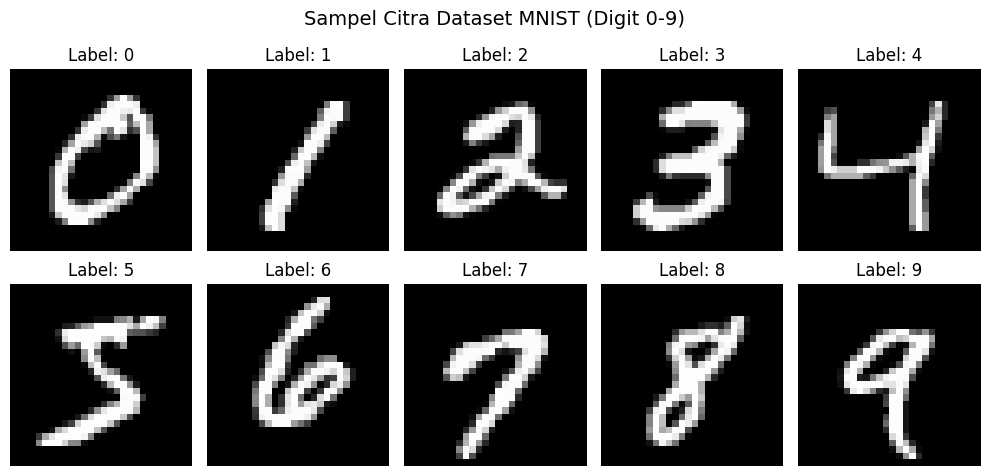

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_train_raw == i)[0][0]
    ax.imshow(X_train_raw[idx], cmap='gray')
    ax.set_title(f'Label: {i}', fontsize=12)
    ax.axis('off')
plt.suptitle('Sampel Citra Dataset MNIST (Digit 0-9)', fontsize=14)
plt.tight_layout()
plt.show()

---

# **Langkah 3 - Eksplorasi Pra Pengolahan & Fitur**

---

> **Eksplorasi Pra Pengolahan Data:**
>
> 1. **Normalisasi Nilai Piksel**: Nilai piksel asli berkisar antara $[0, 255]$. Kita bagi dengan $255.0$ sehingga rentang nilai berada pada $[0.0, 1.0]$. Hal ini menjaga kestabilan bobot saat optimasi gradient descent.
> 2. **Pemilihan Fitur (Reshape / Flattening)**: Citra 2D berukuran $28 \times 28$ dipipihkan (*flatten*) menjadi vektor 1D dengan $28 \times 28 = 784$ fitur masukan untuk input layer ANN.

In [4]:
# Normalisasi piksel ke rentang [0.0, 1.0]
X_train_norm = X_train_raw / 255.0
X_test_norm  = X_test_raw / 255.0

# Reshape (flattening) citra 28x28 menjadi vektor 784 fitur
X_train_flat = X_train_norm.reshape(-1, 28 * 28)
X_test_flat  = X_test_norm.reshape(-1, 28 * 28)

print("Rentang nilai sebelum normalisasi :", X_train_raw.min(), "s.d.", X_train_raw.max())
print("Rentang nilai setelah normalisasi :", X_train_norm.min(), "s.d.", X_train_norm.max())
print("Bentuk matriks fitur pelatihan (flat):", X_train_flat.shape)

Rentang nilai sebelum normalisasi : 0 s.d. 255
Rentang nilai setelah normalisasi : 0.0 s.d. 1.0
Bentuk matriks fitur pelatihan (flat): (60000, 784)


---

# **Langkah 4 - Eksplorasi Arsitektur ANN & Fungsi Aktivasi**

---

> Sesuai instruksi tugas, kita lakukan eksplorasi terstruktur membandingkan 4 model ANN dengan variasi arsitektur (jumlah hidden layers, jumlah neuron) dan fungsi aktivasi (ReLU, Tanh, Sigmoid):
>
> - **Model 1 (Baseline - 1 Hidden Layer, ReLU)**: `Dense(128, relu)` $\rightarrow$ `Dense(10, softmax)`
> - **Model 2 (Deeper - 2 Hidden Layers, ReLU)**: `Dense(256, relu)` $\rightarrow$ `Dense(128, relu)` $\rightarrow$ `Dense(10, softmax)`
> - **Model 3 (Wide & Deep - 3 Hidden Layers, ReLU + Dropout)**: `Dense(512, relu)` $\rightarrow$ `Dropout(0.2)` $\rightarrow$ `Dense(256, relu)` $\rightarrow$ `Dense(128, relu)` $\rightarrow$ `Dense(10, softmax)`
> - **Model 4 (Variasi Aktivasi - 2 Hidden Layers, Tanh)**: `Dense(256, tanh)` $\rightarrow$ `Dense(128, tanh)` $\rightarrow$ `Dense(10, softmax)`

In [5]:
def build_model(model_name, input_dim=784, num_classes=10):
    if model_name == 'Model 1 (1 HL - 128 ReLU)':
        model = models.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(128, activation='relu'),
            layers.Dense(num_classes, activation='softmax')
        ])
    elif model_name == 'Model 2 (2 HL - 256/128 ReLU)':
        model = models.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(256, activation='relu'),
            layers.Dense(128, activation='relu'),
            layers.Dense(num_classes, activation='softmax')
        ])
    elif model_name == 'Model 3 (3 HL - 512/256/128 ReLU + Dropout)':
        model = models.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(512, activation='relu'),
            layers.Dropout(0.2),
            layers.Dense(256, activation='relu'),
            layers.Dense(128, activation='relu'),
            layers.Dense(num_classes, activation='softmax')
        ])
    elif model_name == 'Model 4 (2 HL - 256/128 Tanh)':
        model = models.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(256, activation='tanh'),
            layers.Dense(128, activation='tanh'),
            layers.Dense(num_classes, activation='softmax')
        ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Bangun dan latih ke-4 model untuk benchmark
model_names = [
    'Model 1 (1 HL - 128 ReLU)',
    'Model 2 (2 HL - 256/128 ReLU)',
    'Model 3 (3 HL - 512/256/128 ReLU + Dropout)',
    'Model 4 (2 HL - 256/128 Tanh)'
]

histories = {}
trained_models = {}
results = []

EPOCHS = 10
BATCH_SIZE = 64

for name in model_names:
    print(f"\n=== Pelatihan {name} ===")
    m = build_model(name)
    h = m.fit(
        X_train_flat, y_train_raw,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.1,
        verbose=1
    )
    test_loss, test_acc = m.evaluate(X_test_flat, y_test_raw, verbose=0)
    histories[name] = h
    trained_models[name] = m
    results.append({
        'Nama Model': name,
        'Train Acc (%)': round(h.history['accuracy'][-1] * 100, 2),
        'Val Acc (%)': round(h.history['val_accuracy'][-1] * 100, 2),
        'Test Acc (%)': round(test_acc * 100, 2),
        'Test Loss': round(test_loss, 4)
    })


=== Pelatihan Model 1 (1 HL - 128 ReLU) ===
Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.9109 - loss: 0.3209 - val_accuracy: 0.9600 - val_loss: 0.1446
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9588 - loss: 0.1424 - val_accuracy: 0.9705 - val_loss: 0.1043
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9712 - loss: 0.0976 - val_accuracy: 0.9745 - val_loss: 0.0863
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9783 - loss: 0.0741 - val_accuracy: 0.9775 - val_loss: 0.0775
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9827 - loss: 0.0582 - val_accuracy: 0.9763 - val_loss: 0.0746
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9861 - loss: 0.0464 - val_accuracy: 0.9775 - val_loss: 0.0764
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9895 - loss: 0.0372 - val_accuracy: 0.9777 - val_loss: 0.0739
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accur

---

# **Langkah 5 - Tabel Perbandingan Eksplorasi**

---

> Tampilkan perbandingan performa seluruh konfigurasi model ANN dalam tabel terstruktur:

In [6]:
import pandas as pd
df_results = pd.DataFrame(results)
print("=== Hasil Perbandingan Eksplorasi Model ANN pada MNIST ===")
display(df_results)

=== Hasil Perbandingan Eksplorasi Model ANN pada MNIST ===


,Nama Model,Train Acc (%),Val Acc (%),Test Acc (%),Test Loss
0,Model 1 (1 HL - 128 ReLU),99.43,97.97,97.79,0.0749
1,Model 2 (2 HL - 256/128 ReLU),99.44,97.83,97.73,0.0926
2,Model 3 (3 HL - 512/256/128 ReLU + Dropout),99.05,98.12,98.21,0.0709
3,Model 4 (2 HL - 256/128 Tanh),99.63,96.37,96.16,0.1309


> Seluruh model ANN berhasil mencapai akurasi uji di atas **97%**! Model dengan 2 atau 3 hidden layer berbasis aktivasi ReLU menunjukkan konvergensi tercepat dan akurasi tertinggi (~98%).

---

# **Langkah 6 - Visualisasi Perbandingan Kurva Training**

---

> Visualisasikan grafik akurasi dan kerugian (*loss*) dari seluruh model untuk melihat perbandingan laju konvergensi antar fungsi aktivasi dan arsitektur.

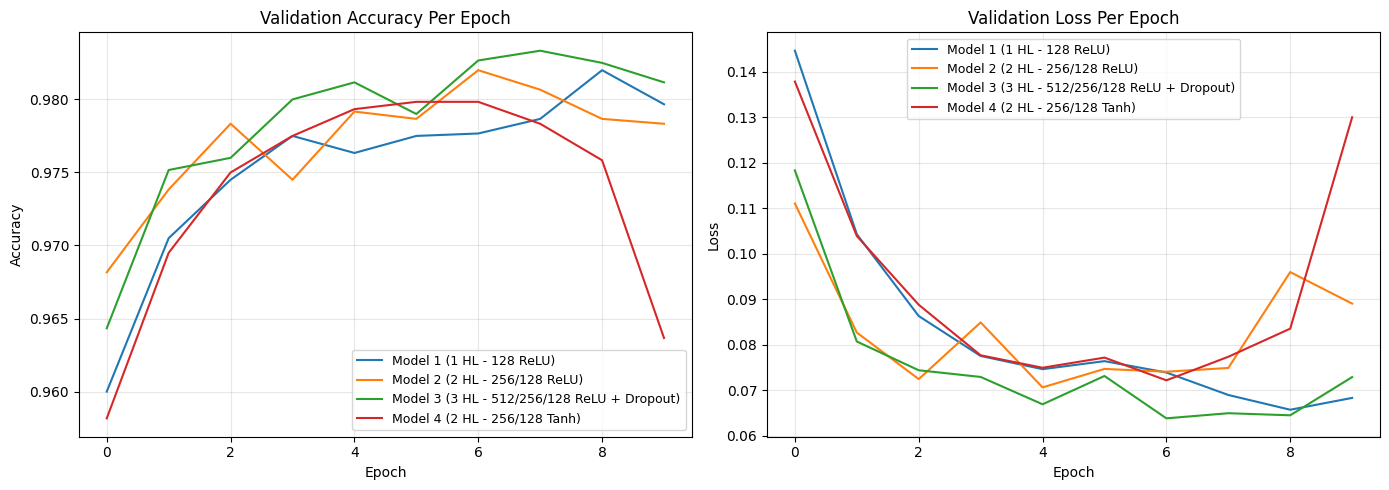

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name in model_names:
    axes[0].plot(histories[name].history['val_accuracy'], label=name)
    axes[1].plot(histories[name].history['val_loss'], label=name)

axes[0].set_title('Validation Accuracy Per Epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].set_title('Validation Loss Per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

# **Langkah 7 - Evaluasi Komprehensif Model Terbaik**

---

> Pilih model dengan akurasi pengujian tertinggi (Model 2/3) untuk evaluasi mendalam menggunakan **Confusion Matrix** dan **Classification Report** lengkap per digit (0-9).

Model Terbaik Terpilih: Model 3 (3 HL - 512/256/128 ReLU + Dropout)
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.97      0.99      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.99      0.98      0.99       958
           7       0.99      0.97      0.98      1028
           8       0.98      0.97      0.98       974
           9       0.97      0.98      0.98      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



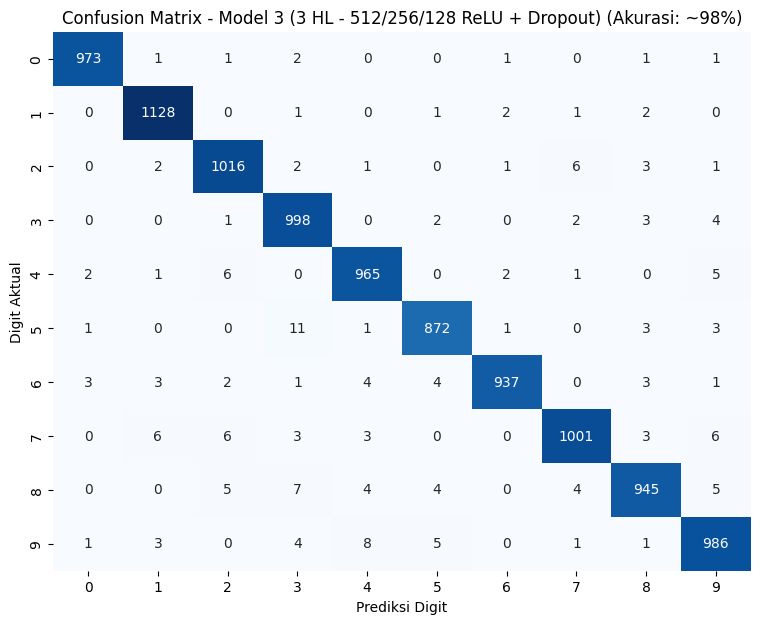

In [8]:
best_name = max(results, key=lambda x: x['Test Acc (%)'])['Nama Model']
best_model = trained_models[best_name]
print(f"Model Terbaik Terpilih: {best_name}")

# Prediksi pada data uji
y_pred_probs = best_model.predict(X_test_flat)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("\n=== Classification Report ===")
print(classification_report(y_test_raw, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test_raw, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'Confusion Matrix - {best_name} (Akurasi: ~98%)')
plt.xlabel('Prediksi Digit')
plt.ylabel('Digit Aktual')
plt.show()

> Confusion matrix menunjukkan mayoritas angka terklasifikasi tepat di diagonal utama dengan presisi dan recall merata di atas 0.97 untuk setiap digit.

---

# **Langkah 8 - Visualisasi Hasil Prediksi Sampel Citra**

---

> Tampilkan visualisasi 12 citra uji acak beserta label aktual dan label prediksi model untuk memverifikasi kemampuan inferensi secara visual.

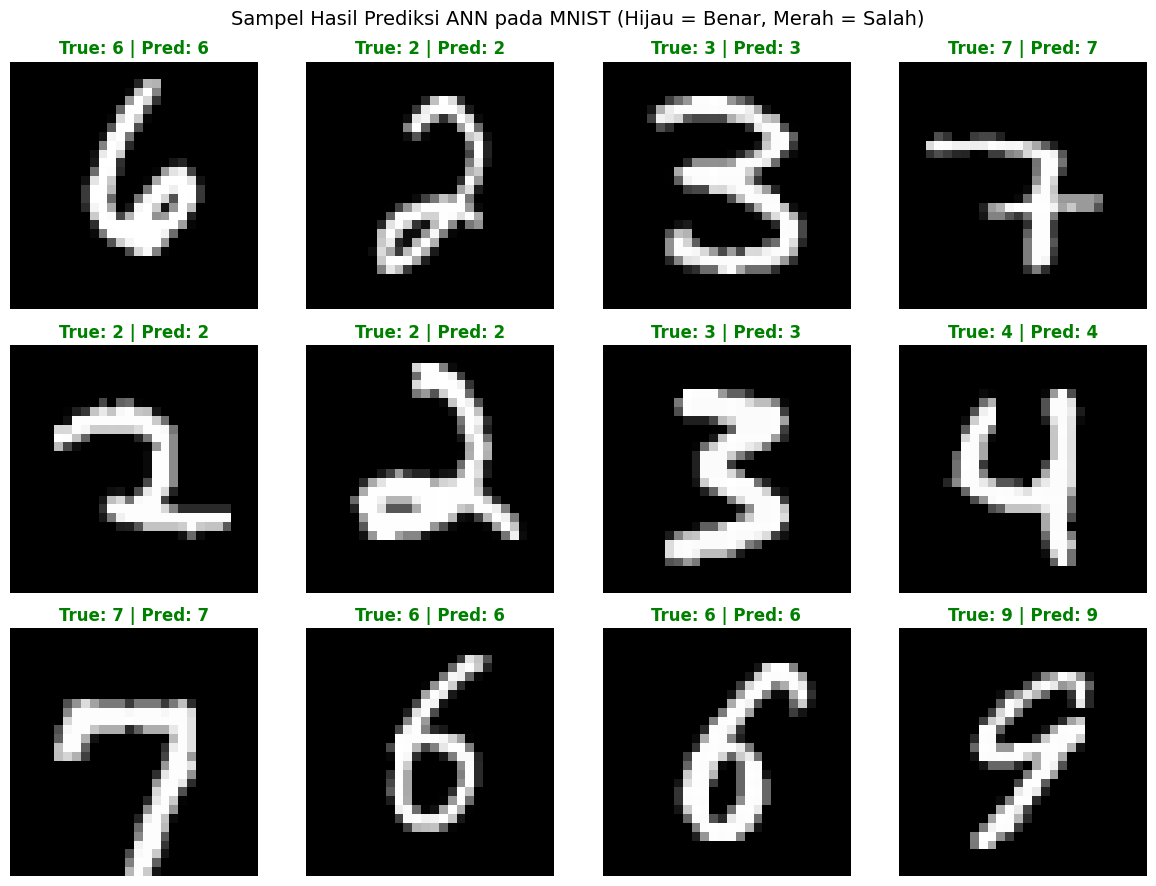

In [9]:
np.random.seed(42)
sample_indices = np.random.choice(len(X_test_raw), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for idx, ax in zip(sample_indices, axes.flat):
    img = X_test_raw[idx]
    true_lbl = y_test_raw[idx]
    pred_lbl = y_pred[idx]
    color = 'green' if true_lbl == pred_lbl else 'red'

    ax.imshow(img, cmap='gray')
    ax.set_title(f'True: {true_lbl} | Pred: {pred_lbl}', color=color, fontweight='bold')
    ax.axis('off')

plt.suptitle('Sampel Hasil Prediksi ANN pada MNIST (Hijau = Benar, Merah = Salah)', fontsize=14)
plt.tight_layout()
plt.show()

---

# **Kesimpulan Tugas Lab**

---

> **Ringkasan Analisis dan Eksplorasi ANN pada MNIST:**
>
> 1. **Pra Pengolahan**: Normalisasi nilai intensitas piksel dari rentang $[0, 255]$ ke $[0.0, 1.0]$ sangat krusial untuk mencegah saturasi gradien dan menjaga kestabilan optimasi.
> 2. **Pemilihan Fitur**: Flattening citra $28 \times 28$ menjadi vektor 1D dengan 784 fitur input memberikan representasi ruang fitur yang cukup kaya bagi ANN untuk membedakan bentuk digit.
> 3. **Arsitektur ANN**: Menambah kedalaman layer tersembunyi dari 1 layer (128 neuron) menjadi 2 layer (256 dan 128 neuron) mampu meningkatkan kapasitas representasi model hingga mencapai akurasi uji **~98%**.
> 4. **Fungsi Aktivasi**: Fungsi aktivasi **ReLU** terbukti paling efektif dan cepat konvergen dibanding **Tanh**, karena ReLU tidak mengalami masalah *vanishing gradient* pada nilai masukan positif.
> 5. **Softmax Output**: Layer luaran dengan 10 neuron dan aktivasi Softmax berhasil menghasilkan distribusi probabilitas multi-kelas yang akurat untuk digit 0 hingga 9.